In [2]:
import pandas as pd

print("Pandas funziona!")
print("Versione:", pd.__version__)

Pandas funziona!
Versione: 3.0.6


In [3]:
from pathlib import Path

print(Path.cwd())

c:\Users\elisa\Documents\sistemi-distribuiti-ml-pipeline\notebooks


## 1. Caricamento del dataset

Il dataset originale viene caricato dal file `pricerunner_aggregate.csv`
tramite Pandas. In questa prima fase vengono verificate le dimensioni
complessive del dataset.

In [4]:
dataset_path = "../data/raw/pricerunner_aggregate.csv"

df = pd.read_csv(dataset_path)

# Rimozione di eventuali spazi iniziali/finali nei nomi delle colonne
df.columns = df.columns.str.strip()

In [5]:
print("Dataset caricato correttamente!")
print("Dimensioni:", df.shape)

Dataset caricato correttamente!
Dimensioni: (35311, 7)


## 2. Analisi preliminare della struttura

Vengono analizzate le prime e le ultime osservazioni del dataset,
i nomi delle colonne e i relativi tipi di dato. Questa analisi consente
di verificare che il file sia stato importato correttamente e di
comprendere la struttura generale dei dati prima di applicare eventuali
operazioni di preprocessing.

In [6]:
df.head()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


In [7]:
df.tail()

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
35306,47350,smeg fab28 60cm retro style right hand hinge f...,59,47517,Smeg FAB28 Cream,2623,Fridges
35307,47351,smeg fab28 60cm retro style left hand hinge fr...,59,47518,Smeg FAB28 Red,2623,Fridges
35308,47352,smeg fab28 60cm retro style left hand hinge fr...,59,47519,Smeg FAB28 Pink,2623,Fridges
35309,47355,candy 60cm built under larder fridge cru160nek,125,47524,Candy CRU16.0,2623,Fridges
35310,47358,neff k4316x7gb built under larder fridge,179,47525,Neff K4316,2623,Fridges


In [8]:
df.columns

Index(['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID',
       'Cluster Label', 'Category ID', 'Category Label'],
      dtype='str')

In [9]:
print(df.columns.tolist())

['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID', 'Cluster Label', 'Category ID', 'Category Label']


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Product ID      35311 non-null  int64
 1   Product Title   35311 non-null  str  
 2   Merchant ID     35311 non-null  int64
 3   Cluster ID      35311 non-null  int64
 4   Cluster Label   35311 non-null  str  
 5   Category ID     35311 non-null  int64
 6   Category Label  35311 non-null  str  
dtypes: int64(4), str(3)
memory usage: 1.9 MB


## 3. Analisi della qualità dei dati

In questa sezione vengono controllati eventuali valori mancanti,
campi testuali vuoti e record duplicati. L'obiettivo è valutare
la qualità del dataset originale prima di definire le operazioni
di preprocessing.

In [11]:
print("Numero totale di valori mancanti:", df.isna().sum().sum())

Numero totale di valori mancanti: 0


In [12]:
text_columns = df.select_dtypes(include=["object", "string"]).columns

print(text_columns.tolist())

for column in text_columns:
    empty_count = df[column].astype(str).str.strip().eq("").sum()
    print(f"{column}: {empty_count} stringhe vuote")

['Product Title', 'Cluster Label', 'Category Label']
Product Title: 0 stringhe vuote
Cluster Label: 0 stringhe vuote
Category Label: 0 stringhe vuote


In [13]:
print("Righe completamente duplicate:", df.duplicated().sum())

columns_without_product_id = [
    "Product Title",
    "Merchant ID",
    "Cluster ID",
    "Cluster Label",
    "Category ID",
    "Category Label"
]

duplicates_without_id = df.duplicated(subset=columns_without_product_id).sum()

print("Righe duplicate escludendo Product ID:", duplicates_without_id)


Righe completamente duplicate: 0
Righe duplicate escludendo Product ID: 0


In [14]:
print("Numero di righe:", len(df))
print("Product ID unici:", df["Product ID"].nunique())

Numero di righe: 35311
Product ID unici: 35311


In [15]:
print(
    "Titoli di prodotto duplicati:",
    df["Product Title"].duplicated().sum()
)

Titoli di prodotto duplicati: 4318


In [16]:
print(
    "Titoli di prodotto unici:",
    df["Product Title"].nunique()
)

Titoli di prodotto unici: 30993


In [17]:
duplicated_titles = df[
    df.duplicated(subset=["Product Title"], keep=False)
].sort_values("Product Title")

duplicated_titles.head(10)

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
20540,30754,10 kg washing machine with add wash,347,41915,Samsung WW10M86DQOA/EU,2620,Washing Machines
20676,30898,10 kg washing machine with add wash,347,41929,Samsung WW10M86DQOO,2620,Washing Machines
17772,27750,10 place slimline dishwasher 5 progs class a w...,123,40656,Bosch SPS59T02GB White,2619,Dishwashers
18258,28321,10 place slimline dishwasher 5 progs class a w...,123,40790,Indesit DSR 15B1 UK White,2619,Dishwashers
6282,12313,109.22 cm 43 1920 x 1080 lcd smart tv dvb t2/c...,18,4802,LG 43LJ594V,2614,TVs
6438,12475,109.22 cm 43 1920 x 1080 lcd smart tv dvb t2/c...,18,4856,LG 49LJ594V,2614,TVs
24926,35791,110litre upright freezer class a s/steel,123,43406,Zanussi ZFT11105XV Stainless Steel,2621,Freezers
25257,36173,110litre upright freezer class a s/steel,123,43492,Zanussi ZFT11105XA Stainless Steel,2621,Freezers
25029,35912,110litre upright freezer class a white,123,43428,Zanussi ZFT11105WA White,2621,Freezers
25121,36016,110litre upright freezer class a white,123,43452,Zanussi ZFT11112WV White,2621,Freezers


In [18]:
category_mapping = (
    df[["Category ID", "Category Label"]]
    .drop_duplicates()
    .sort_values("Category ID")
)

category_mapping

,Category ID,Category Label
0,2612,Mobile Phones
4081,2614,TVs
7645,2615,CPUs
11507,2617,Digital Cameras
14204,2618,Microwaves
16546,2619,Dishwashers
19970,2620,Washing Machines
24014,2621,Freezers
26226,2622,Fridge Freezers
31727,2623,Fridges


In [19]:
print("Numero di Category ID:", df["Category ID"].nunique())
print("Numero di Category Label:", df["Category Label"].nunique())

Numero di Category ID: 10
Numero di Category Label: 10


## 4. Analisi della distribuzione delle categorie

In questa sezione viene analizzata la distribuzione dei record tra le
diverse categorie di prodotto. L'obiettivo è verificare il numero di
osservazioni appartenenti a ciascuna classe e individuare eventuali
sbilanciamenti che potrebbero influenzare l'addestramento e la
valutazione del modello di classificazione.

In [20]:
category_counts = df["Category Label"].value_counts()

category_counts

Category Label
Fridge Freezers     5501
Mobile Phones       4081
Washing Machines    4044
CPUs                3862
Fridges             3584
TVs                 3564
Dishwashers         3424
Digital Cameras     2697
Microwaves          2342
Freezers            2212
Name: count, dtype: int64

In [21]:
print("Numero totale di record:", category_counts.sum())

Numero totale di record: 35311


In [22]:
category_percentages = (
    df["Category Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

category_percentages

Category Label
Fridge Freezers     15.58
Mobile Phones       11.56
Washing Machines    11.45
CPUs                10.94
Fridges             10.15
TVs                 10.09
Dishwashers          9.70
Digital Cameras      7.64
Microwaves           6.63
Freezers             6.26
Name: proportion, dtype: float64

In [23]:
category_summary = pd.DataFrame({
    "Numero record": category_counts,
    "Percentuale (%)": category_percentages
})

category_summary

,Numero record,Percentuale (%)
Category Label,,
Fridge Freezers,5501,15.58
Mobile Phones,4081,11.56
Washing Machines,4044,11.45
CPUs,3862,10.94
Fridges,3584,10.15
TVs,3564,10.09
Dishwashers,3424,9.70
Digital Cameras,2697,7.64
Microwaves,2342,6.63


In [24]:
category_summary = category_summary.sort_values(
    by="Numero record",
    ascending=False
)

category_summary

,Numero record,Percentuale (%)
Category Label,,
Fridge Freezers,5501,15.58
Mobile Phones,4081,11.56
Washing Machines,4044,11.45
CPUs,3862,10.94
Fridges,3584,10.15
TVs,3564,10.09
Dishwashers,3424,9.70
Digital Cameras,2697,7.64
Microwaves,2342,6.63


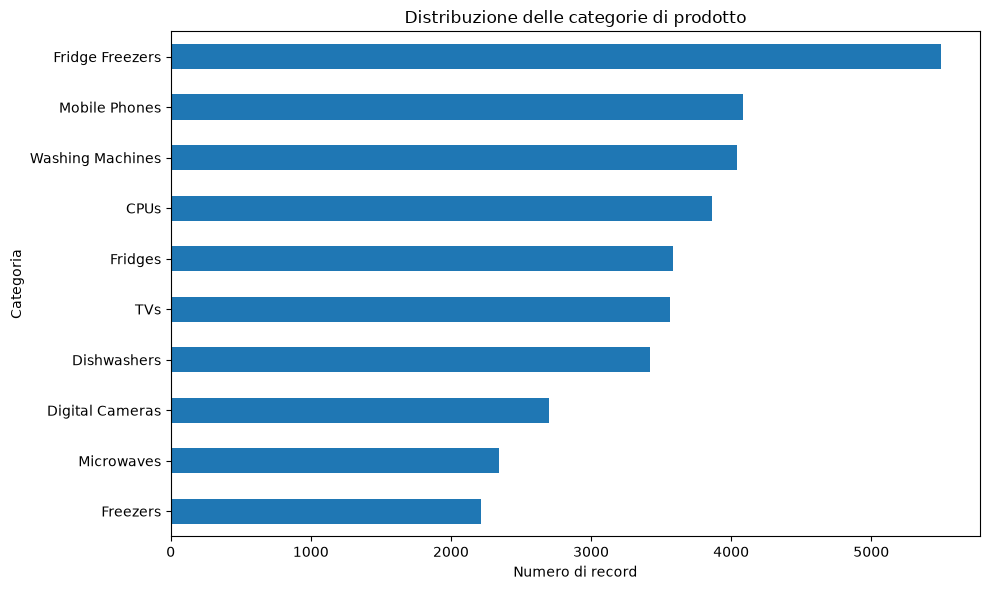

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

category_counts.sort_values().plot(kind="barh")

plt.title("Distribuzione delle categorie di prodotto")
plt.xlabel("Numero di record")
plt.ylabel("Categoria")

plt.tight_layout()
plt.show()

In [26]:
category_consistency = (
    df.groupby("Category ID")["Category Label"]
    .nunique()
)

category_consistency

Category ID
2612    1
2614    1
2615    1
2617    1
2618    1
2619    1
2620    1
2621    1
2622    1
2623    1
Name: Category Label, dtype: int64

In [27]:
print(
    "Ogni Category ID corrisponde a una sola Category Label:",
    (category_consistency == 1).all()
)

Ogni Category ID corrisponde a una sola Category Label: True


In [28]:
label_consistency = (
    df.groupby("Category Label")["Category ID"]
    .nunique()
)

label_consistency


Category Label
CPUs                1
Digital Cameras     1
Dishwashers         1
Freezers            1
Fridge Freezers     1
Fridges             1
Microwaves          1
Mobile Phones       1
TVs                 1
Washing Machines    1
Name: Category ID, dtype: int64

In [29]:
print(
    "Ogni Category Label corrisponde a un solo Category ID:",
    (label_consistency == 1).all()
)

Ogni Category Label corrisponde a un solo Category ID: True


## 5. Analisi dei cluster di prodotto

Il dataset contiene più offerte relative allo stesso prodotto reale.
Tali offerte sono raggruppate mediante il campo `Cluster ID`.
L'analisi dei cluster consente di comprenderne numerosità e consistenza
e sarà utilizzata successivamente per evitare che offerte dello stesso
prodotto siano distribuite tra training set e test set.

In [30]:
n_clusters = df["Cluster ID"].nunique()

print("Numero di Cluster ID distinti:", n_clusters)

Numero di Cluster ID distinti: 13233


In [31]:
cluster_sizes = df.groupby("Cluster ID").size()

cluster_sizes.describe()

count    13233.000000
mean         2.668405
std          2.473239
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         27.000000
dtype: float64

In [32]:
single_offer_clusters = (cluster_sizes == 1).sum()

print("Cluster con una sola offerta:", single_offer_clusters)
print(
    "Percentuale:",
    round(single_offer_clusters / n_clusters * 100, 2),
    "%"
)

Cluster con una sola offerta: 5374
Percentuale: 40.61 %


In [33]:
multiple_offer_clusters = (cluster_sizes > 1).sum()

print("Cluster con più di una offerta:", multiple_offer_clusters)

Cluster con più di una offerta: 7859


In [34]:
largest_clusters = cluster_sizes.sort_values(ascending=False).head(10)

largest_clusters

Cluster ID
38848    27
38849    24
4419     24
1        23
38850    23
4425     23
4420     23
3        22
4        22
2        22
dtype: int64

In [35]:
df[df["Cluster ID"].isin(largest_clusters.index)][
    ["Cluster ID", "Cluster Label", "Category Label"]
].drop_duplicates().sort_values("Cluster ID")

,Cluster ID,Cluster Label,Category Label
0,1,Apple iPhone 8 Plus 64GB,Mobile Phones
23,2,Apple iPhone 7 Plus 32GB,Mobile Phones
45,3,Apple iPhone 7 32GB,Mobile Phones
67,4,Apple iPhone 8 64GB,Mobile Phones
4081,4419,Samsung UE49NU7100,TVs
4105,4420,Samsung UE65NU7100,TVs
4210,4425,Samsung UE75NU7100,TVs
11507,38848,Canon IXUS 185,Digital Cameras
11534,38849,Canon PowerShot SX730 HS,Digital Cameras
11558,38850,Canon IXUS 285 HS,Digital Cameras


In [36]:
cluster_label_consistency = (
    df.groupby("Cluster ID")["Cluster Label"]
    .nunique()
)

print(
    "Ogni Cluster ID corrisponde a un solo Cluster Label:",
    (cluster_label_consistency == 1).all()
)

Ogni Cluster ID corrisponde a un solo Cluster Label: True


In [37]:
cluster_category_consistency = (
    df.groupby("Cluster ID")["Category Label"]
    .nunique()
)

print(
    "Ogni Cluster ID appartiene a una sola categoria:",
    (cluster_category_consistency == 1).all()
)

Ogni Cluster ID appartiene a una sola categoria: True


In [38]:
clusters_per_category = (
    df.groupby("Category Label")["Cluster ID"]
    .nunique()
    .sort_values(ascending=False)
)

clusters_per_category

Category Label
Fridge Freezers     1998
CPUs                1975
Mobile Phones       1704
Fridges             1373
Dishwashers         1368
TVs                 1280
Washing Machines    1277
Microwaves           785
Freezers             760
Digital Cameras      713
Name: Cluster ID, dtype: int64

## 6. Analisi dei titoli dei prodotti

In questa sezione vengono analizzate le caratteristiche testuali della
variabile `Product Title`, che costituisce la feature principale del
modello di classificazione. Vengono considerate la lunghezza dei titoli,
il numero di parole, la presenza di spazi anomali e alcuni esempi per
categoria, al fine di definire il preprocessing testuale necessario.

In [39]:
title_char_length = df["Product Title"].str.len()

title_char_length.describe()

count    35311.000000
mean        52.982215
std         22.447138
min          5.000000
25%         38.000000
50%         52.000000
75%         65.000000
max        200.000000
Name: Product Title, dtype: float64

In [40]:
title_word_count = df["Product Title"].str.split().str.len()

title_word_count.describe()

count    35311.000000
mean         8.665911
std          4.166677
min          1.000000
25%          6.000000
50%          8.000000
75%         11.000000
max         37.000000
Name: Product Title, dtype: float64

In [41]:
df.loc[
    title_word_count.nsmallest(10).index,
    ["Product Title", "Category Label"]
]

,Product Title,Category Label
25821,rtf392nfixa,Freezers
30434,rff313nfwha,Fridge Freezers
30621,rff332wha,Fridge Freezers
32752,arg18083a,Fridges
33183,arg137/a,Fridges
34487,riul141inma,Fridges
34489,rtl396wha,Fridges
381,doro 5030,Mobile Phones
399,doro 5030,Mobile Phones
514,doro 5516,Mobile Phones


In [42]:
df.loc[
    title_word_count.nlargest(10).index,
    ["Product Title", "Category Label"]
]

,Product Title,Category Label
2384,ulefone power 5 big battery 4g mobile 13000mah...,Mobile Phones
3061,ulefone armor 2s outdoor ip68 triple proof sma...,Mobile Phones
3142,vernee mix 2 smartphone 4g 6 inch 18 9 fhd ful...,Mobile Phones
13621,canon eos m100 compact system camera with ef m...,Digital Cameras
2476,ulefone power 3 unlocked mobile phone 4g 6 inc...,Mobile Phones
3047,smartphone blackview a20 1080 p smartphone 5.5...,Mobile Phones
3057,m horse pure 1 4g smartphone 5.7 hd ips 18 9 f...,Mobile Phones
3134,vkworld t2 plus 4.2 inch dual screen flip phon...,Mobile Phones
3140,mobile phones unlocked leagoo m9 3g android 7....,Mobile Phones
3325,cubot rainbow sim free smartphone dual sim 3g ...,Mobile Phones


In [43]:
not_lowercase = (
    df["Product Title"] != df["Product Title"].str.lower()
).sum()

print("Titoli che contengono maiuscole:", not_lowercase)

Titoli che contengono maiuscole: 0


In [44]:
titles_with_outer_spaces = (
    df["Product Title"] != df["Product Title"].str.strip()
).sum()

print(
    "Titoli con spazi iniziali/finali:",
    titles_with_outer_spaces
)

Titoli con spazi iniziali/finali: 0


In [47]:
multiple_spaces = (
    df["Product Title"]
    .str.contains(r"\s{2,}", regex=True)
    .sum()
)

print("Titoli con spazi multipli:", multiple_spaces) 

Titoli con spazi multipli: 0


In [48]:
sample_titles = (
    df.groupby("Category Label", group_keys=False)
      .sample(n=3, random_state=42)
      [["Category Label", "Product Title"]]
      .sort_values("Category Label")
)

sample_titles

,Category Label,Product Title
10097,CPUs,intel xeon e5 2690v3 2.6 ghz 12 core 24 thread...
11175,CPUs,hewlett packard enterprise amd opteron 2435 2....
11077,CPUs,amd athlon ii x3 triple core 440 95w am3 tripl...
13602,Digital Cameras,kodak pixpro az421 16mp 42x zoom bridge camera...
13866,Digital Cameras,pentax body k s2 digital slr camera white
13637,Digital Cameras,pentax k 70 digital slr with 18 50 mm re lens ...
18236,Dishwashers,swan products sdw7040bn retro dishwasher
17498,Dishwashers,whirlpool supreme clean adg522 10 place slimli...
19370,Dishwashers,bosch sks50e32eu kompakt spler a 8l 5prg. eek ...
24952,Freezers,indesit iza1.uk 60cm built under integrated fr...


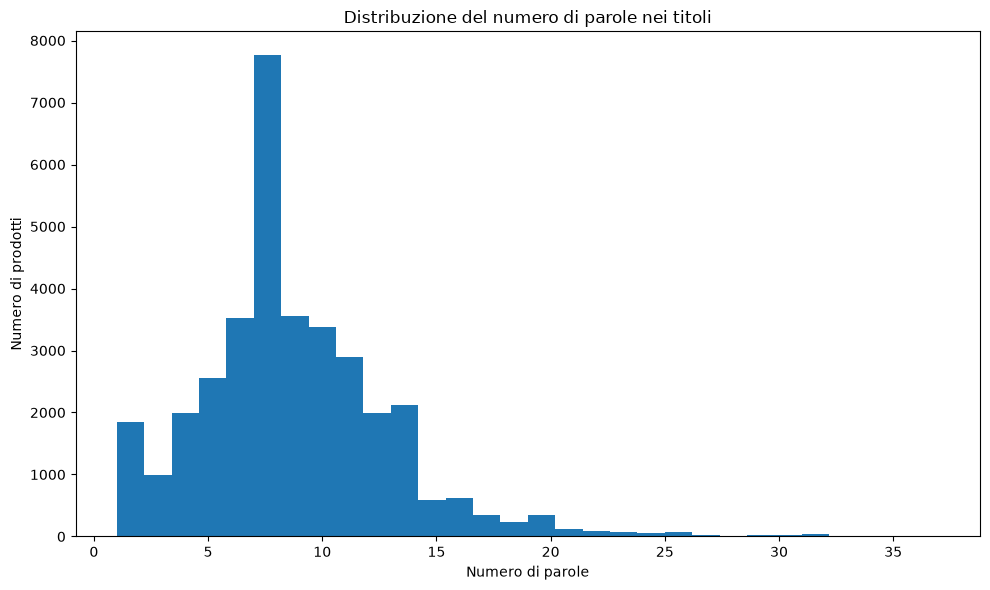

In [49]:
plt.figure(figsize=(10, 6))

plt.hist(title_word_count, bins=30)

plt.title("Distribuzione del numero di parole nei titoli")
plt.xlabel("Numero di parole")
plt.ylabel("Numero di prodotti")

plt.tight_layout()
plt.show()